# Chapter 14: Equality Is a Promise

*Math Class Didn't Show Its Work* by Jason Karpeles

In this notebook you will test whether a number keeps an equation's promise, see why every step must treat both sides alike, find out why it is fair to subtract an unknown from both sides, and meet the one place where an inequality turns around.

**A note on the code.** The code cells are optional reading. Every result and every picture is shown right below the cell that makes it, so you can follow along without running anything. If you do want to experiment, change a number in a cell and run it again.

## Setup

This one cell loads two common tools, numpy (for lists of numbers) and matplotlib (for pictures), and a few small helpers that tidy the output.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
%matplotlib inline

TEAL, NAVY, GOLD, RED, GREY = "#0f6268", "#172a3b", "#b8860b", "#b5472f", "#8a949a"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

def finish(fig):
    """Tidy the layout and show the picture."""
    fig.tight_layout()
    plt.show()

def q(v):
    """Write a Fraction the way we would by hand: 3/2, or 5 when whole."""
    v = Fraction(v)
    return str(v.numerator) if v.denominator == 1 else f"{v.numerator}/{v.denominator}"

def par(v):
    """Wrap negative numbers in parentheses, the way we do when substituting."""
    s = q(v)
    return f"({s})" if Fraction(v) < 0 else s

## 1. Test a candidate

**The question:** For $3x + 5 = 20$, which inputs make the promise true?

**The equation from the chapter:**

$$3x + 5 = 20$$

**What the symbols mean:** $x$ can be any number. The left side $3x + 5$ changes as $x$ changes; the right side stays at 20. A *solution* is a value that makes both sides match.

Predict first: if you try $x = 7$, will the left side overshoot 20, and by how much?

In [2]:
for x in (2, 5, 7):
    left = 3 * x + 5
    verdict = "true" if left == 20 else "false"
    print(f"x = {x}: left side 3({x}) + 5 = {3 * x} + 5 = {left}; right side = 20; equation is {verdict}")

x = 5
print()
print(f"Default candidate x = {x}:")
print(f"  substitute: 3({x}) + 5 = {3 * x} + 5 = {3 * x + 5}")
print(f"  compare: {3 * x + 5} against 20, so {x} belongs to the solution set.")
print()
x = 7
print(f"Overshoot at x = {x}: {3 * x + 5} - 20 = {3 * x + 5 - 20}")

x = 2: left side 3(2) + 5 = 6 + 5 = 11; right side = 20; equation is false
x = 5: left side 3(5) + 5 = 15 + 5 = 20; right side = 20; equation is true
x = 7: left side 3(7) + 5 = 21 + 5 = 26; right side = 20; equation is false

Default candidate x = 5:
  substitute: 3(5) + 5 = 15 + 5 = 20
  compare: 20 against 20, so 5 belongs to the solution set.

Overshoot at x = 7: 26 - 20 = 6


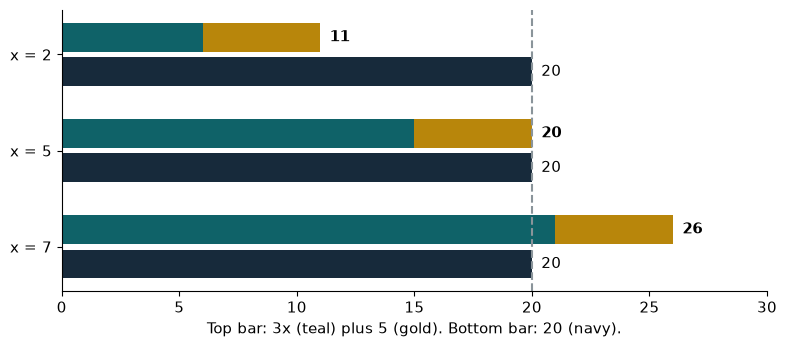

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
cands = [2, 5, 7]
for i, x in enumerate(cands):
    y = 2 - i
    ax.barh(y + 0.18, 3 * x, height=0.3, color=TEAL)
    ax.barh(y + 0.18, 5, left=3 * x, height=0.3, color=GOLD)
    ax.barh(y - 0.18, 20, height=0.3, color=NAVY)
    ax.text(3 * x + 5 + 0.4, y + 0.18, str(3 * x + 5), va="center", fontweight="bold")
    ax.text(20.4, y - 0.18, "20", va="center")
ax.axvline(20, color=GREY, linestyle="dashed")
ax.set_yticks([2, 1, 0]); ax.set_yticklabels([f"x = {x}" for x in cands])
ax.set_xlabel("Top bar: 3x (teal) plus 5 (gold). Bottom bar: 20 (navy).")
ax.set_xlim(0, 30)
finish(fig)

**What this shows.** The equation is true only where the two bars end in the same place. At $x = 5$ they do. At 2 the left bar is short (11) and at 7 it overshoots (26).

**Where it stops working.** Three tries cannot prove there is no other solution. Solving, which means making equal changes to both sides, does that job and finds the single solution 5.

## 2. Keep the pans balanced

**The question:** Why must you do the same thing to both sides?

**The equations from the chapter:**

$$3x + 5 - 5 = 20 - 5 \qquad\qquad \frac{3x}{3} = \frac{15}{3}$$

**What the symbols mean:** Picture a balance. Each tall block is one $x$. Each small square is one unit. The equals sign says the two pans have the same total.

Predict first: if you take the 5 units off the left pan only, will the last line still say $x = 5$?

In [4]:
print("BOTH PANS CHANGE (the fair way)")
print("  start:       3x + 5 = 20")
print("  remove 5:    3x + 5 - 5 = 20 - 5")
print("               3x = 15")
print("  split in 3:  (3x) / 3 = 15 / 3")
print("               x = 5")
print("  check in the original: 3(5) + 5 = 15 + 5 = 20, and the right side is 20. It works.")
print()
print("LEFT PAN ONLY (the mistake)")
print("  start:       3x + 5 = 20")
print("  remove 5 from the left only:  3x = 20   (a different equation)")
x = Fraction(20, 3)
print(f"  split in 3:  x = 20 / 3 = {q(x)}")
print(f"  check 20/3 in the original: 3 x 20/3 + 5 = 20 + 5 = {3 * x + 5}, not 20.")
print("  Changing one side changed the question.")
print()
print("PRACTICE MISTAKE: divide only the left side by 3 at the start")
print("  (3x + 5) / 3 = 20, so 3x + 5 = 60, so 3x = 55, so x = 55/3")
x = Fraction(55, 3)
print(f"  check: 3 x 55/3 + 5 = 55 + 5 = {3 * x + 5}, not 20.")

BOTH PANS CHANGE (the fair way)
  start:       3x + 5 = 20
  remove 5:    3x + 5 - 5 = 20 - 5
               3x = 15
  split in 3:  (3x) / 3 = 15 / 3
               x = 5
  check in the original: 3(5) + 5 = 15 + 5 = 20, and the right side is 20. It works.

LEFT PAN ONLY (the mistake)
  start:       3x + 5 = 20
  remove 5 from the left only:  3x = 20   (a different equation)
  split in 3:  x = 20 / 3 = 20/3
  check 20/3 in the original: 3 x 20/3 + 5 = 20 + 5 = 25, not 20.
  Changing one side changed the question.

PRACTICE MISTAKE: divide only the left side by 3 at the start
  (3x + 5) / 3 = 20, so 3x + 5 = 60, so 3x = 55, so x = 55/3
  check: 3 x 55/3 + 5 = 55 + 5 = 60, not 20.


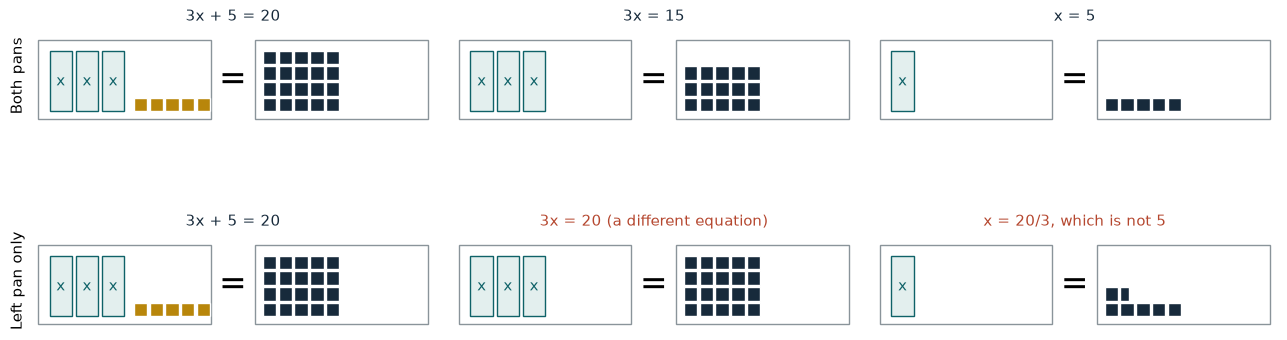

In [5]:
def pans(ax, xs, left_units, right_units, title, bad=False):
    """Draw x-blocks and unit squares on a left pan, unit squares on a right pan."""
    ax.add_patch(plt.Rectangle((-0.2, 0), 4.6, 2.1, fill=False, edgecolor=GREY))
    ax.add_patch(plt.Rectangle((5.6, 0), 4.6, 2.1, fill=False, edgecolor=GREY))
    for k in range(xs):
        ax.add_patch(plt.Rectangle((0.1 + k * 0.7, 0.2), 0.6, 1.6, facecolor="#e3efee", edgecolor=TEAL))
        ax.text(0.4 + k * 0.7, 1.0, "x", ha="center", va="center", color=TEAL)
    def squares(x0, units, color):
        whole = int(units); part = float(Fraction(units) - whole)
        cells = [(k, 1.0) for k in range(whole)] + ([(whole, part)] if part else [])
        for k, f in cells:
            r, c = divmod(k, 5)
            ax.add_patch(plt.Rectangle((x0 + c * 0.42, 0.2 + r * 0.42), 0.36 * f, 0.36, facecolor=color, edgecolor="white"))
    squares(0.1 + xs * 0.7 + 0.15, left_units, GOLD)
    squares(5.8, right_units, NAVY)
    ax.text(5.0, 1.05, "=", ha="center", va="center", fontsize=24)
    ax.set_title(title, color=RED if bad else NAVY, fontsize=11)
    ax.set_xlim(-0.4, 10.4); ax.set_ylim(-0.1, 2.4)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

fig, axes = plt.subplots(2, 3, figsize=(13, 5.2))
pans(axes[0][0], 3, 5, 20, "3x + 5 = 20")
pans(axes[0][1], 3, 0, 15, "3x = 15")
pans(axes[0][2], 1, 0, 5, "x = 5")
pans(axes[1][0], 3, 5, 20, "3x + 5 = 20")
pans(axes[1][1], 3, 0, 20, "3x = 20 (a different equation)", bad=True)
pans(axes[1][2], 1, 0, Fraction(20, 3), "x = 20/3, which is not 5", bad=True)
axes[0][0].set_ylabel("Both pans", fontsize=11)
axes[1][0].set_ylabel("Left pan only", fontsize=11)
finish(fig)

**What this shows.** Take 5 from both pans and they stay level, leaving $3x = 15$. Split both into three equal groups and one $x$ is 5. Take 5 from one pan alone and you have quietly written a new equation with a different answer.

**Where it stops working.** Each step must be undoable, so you can never divide by zero (here the divisor 3 is fine). A step done to one side only is not undoable this way, and it loses the original solution.

## 3. Unknowns on both sides

**The question:** In $5x - 7 = 2x + 8$, why is it fair to subtract $2x$ before you know $x$?

**The equations from the chapter:**

$$5x - 7 = 2x + 8 \qquad\qquad 3x - 7 = 8$$

**What the symbols mean:** $x$ is the unknown. We evaluate each side at a chosen $x$ and look at *left minus right*, the gap between them.

Predict first: at $x = 3$ the original sides are 8 and 14. After subtracting $2x$ from both sides, will the gap still be $-6$?

In [6]:
x = 5
L, R = 5 * x - 7, 2 * x + 8
print(f"ORIGINAL at x = {x}:")
print(f"  left:  5({x}) - 7 = {5 * x} - 7 = {L}")
print(f"  right: 2({x}) + 8 = {2 * x} + 8 = {R}")
print(f"  gap (left minus right) = {L} - {R} = {L - R}")
print()
L2, R2 = 3 * x - 7, 8
print(f"AFTER subtracting 2x ({2 * x}) from both sides, at x = {x}:")
print(f"  left:  3({x}) - 7 = {3 * x} - 7 = {L2}")
print(f"  right: 8")
print(f"  gap = {L2} - {R2} = {L2 - R2}")
print()
print("Both forms, every x from 3 to 6:")
for v in (3, 4, 5, 6):
    g1 = (5 * v - 7) - (2 * v + 8)
    g2 = (3 * v - 7) - 8
    print(f"  x = {v}: original {5*v-7} vs {2*v+8}, gap {g1};   reduced {3*v-7} vs 8, gap {g2};   3({v}) - 15 = {3*v-15}")
print()
print("The gap is 3x - 15 in both forms, and it is zero only at x = 5.")

ORIGINAL at x = 5:
  left:  5(5) - 7 = 25 - 7 = 18
  right: 2(5) + 8 = 10 + 8 = 18
  gap (left minus right) = 18 - 18 = 0

AFTER subtracting 2x (10) from both sides, at x = 5:
  left:  3(5) - 7 = 15 - 7 = 8
  right: 8
  gap = 8 - 8 = 0

Both forms, every x from 3 to 6:
  x = 3: original 8 vs 14, gap -6;   reduced 2 vs 8, gap -6;   3(3) - 15 = -6
  x = 4: original 13 vs 16, gap -3;   reduced 5 vs 8, gap -3;   3(4) - 15 = -3
  x = 5: original 18 vs 18, gap 0;   reduced 8 vs 8, gap 0;   3(5) - 15 = 0
  x = 6: original 23 vs 20, gap 3;   reduced 11 vs 8, gap 3;   3(6) - 15 = 3

The gap is 3x - 15 in both forms, and it is zero only at x = 5.


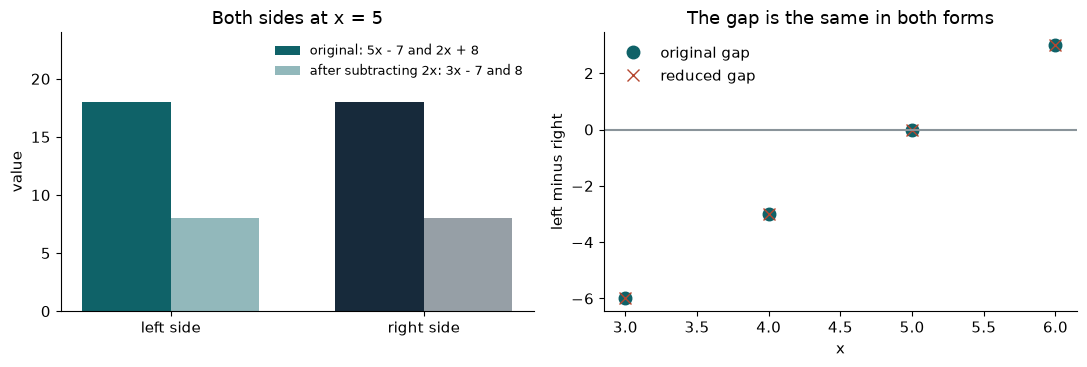

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
x = 5
w = 0.35
a1.bar(np.array([0, 1]) - w / 2, [5 * x - 7, 2 * x + 8], w, color=[TEAL, NAVY], label="original: 5x - 7 and 2x + 8")
a1.bar(np.array([0, 1]) + w / 2, [3 * x - 7, 8], w, color=[TEAL, NAVY], alpha=0.45, label="after subtracting 2x: 3x - 7 and 8")
a1.set_xticks([0, 1]); a1.set_xticklabels(["left side", "right side"])
a1.set_title(f"Both sides at x = {x}")
a1.set_ylabel("value"); a1.legend(frameon=False, fontsize=9)
a1.set_ylim(0, 24)
xs = np.linspace(3, 6, 4)
a2.plot(xs, (5 * xs - 7) - (2 * xs + 8), "o", color=TEAL, markersize=9, label="original gap")
a2.plot(xs, (3 * xs - 7) - 8, "x", color=RED, markersize=9, label="reduced gap")
a2.axhline(0, color=GREY)
a2.set_xlabel("x"); a2.set_ylabel("left minus right")
a2.set_title("The gap is the same in both forms")
a2.legend(frameon=False)
finish(fig)

**What this shows.** Subtracting $2x$ takes the same amount off both bars, whatever $x$ is. Both bars drop, but the gap between them does not change, so the solution cannot change either. The gap, $3x - 15$, hits zero at $x = 5$ and nowhere else.

**Where it stops working.** $x$ may be any number here. Subtracting $2x$ is undoable (just add $2x$ back), which is why it is safe.

## 4. The one reversal

**The question:** Solving $-2x + 3 \le 11$, why does the sign flip when you divide by $-2$?

**The equations from the chapter:**

$$-2x + 3 \le 11 \qquad\qquad x \ge -4$$

**What the symbols mean:** $\le$ means "less than or equal to" and $\ge$ means "greater than or equal to". The shaded part of a number line is the claimed solution set.

Predict first: if you keep the sign instead of reversing it and then test $x = 0$, does the shaded answer agree with the original?

In [8]:
print("Solve -2x + 3 <= 11")
print("  subtract 3 from both sides: -2x + 3 - 3 <= 11 - 3, so -2x <= 8   (no reversal here)")
print("  divide both sides by -2: x >= 8 / (-2) = -4   (a negative divisor reverses the sign)")
print()
print("Reflection reason: 2 < 5, but multiplying by -1 gives -2 and -5, and -2 > -5. The order swapped.")
print()
for test in (-5, -4, 0):
    value = -2 * test + 3
    true = value <= 11
    right_rule = test >= -4
    wrong_rule = test <= -4
    print(f"test x = {test}: -2({test}) + 3 = {-2 * test} + 3 = {value}; is {value} <= 11? {true}")
    print(f"    correct shading x >= -4 includes {test}? {right_rule}  -> {'agrees' if right_rule == true else 'WRONG'}")
    print(f"    error shading   x <= -4 includes {test}? {wrong_rule}  -> {'agrees' if wrong_rule == true else 'WRONG'}")

Solve -2x + 3 <= 11
  subtract 3 from both sides: -2x + 3 - 3 <= 11 - 3, so -2x <= 8   (no reversal here)
  divide both sides by -2: x >= 8 / (-2) = -4   (a negative divisor reverses the sign)

Reflection reason: 2 < 5, but multiplying by -1 gives -2 and -5, and -2 > -5. The order swapped.

test x = -5: -2(-5) + 3 = 10 + 3 = 13; is 13 <= 11? False
    correct shading x >= -4 includes -5? False  -> agrees
    error shading   x <= -4 includes -5? True  -> WRONG
test x = -4: -2(-4) + 3 = 8 + 3 = 11; is 11 <= 11? True
    correct shading x >= -4 includes -4? True  -> agrees
    error shading   x <= -4 includes -4? True  -> agrees
test x = 0: -2(0) + 3 = 0 + 3 = 3; is 3 <= 11? True
    correct shading x >= -4 includes 0? True  -> agrees
    error shading   x <= -4 includes 0? False  -> WRONG


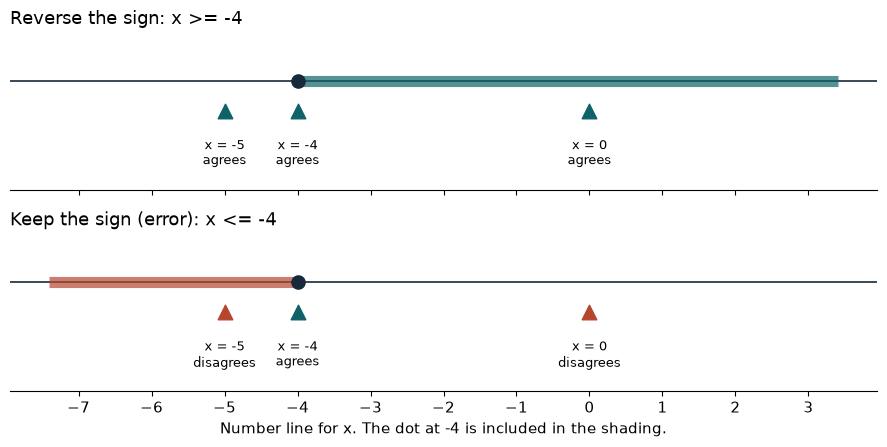

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(9, 4.6), sharex=True)
tests = [-5, -4, 0]
for ax, label, lo, hi, ok in [(axes[0], "Reverse the sign: x >= -4", -4, 3.4, lambda t: t >= -4),
                              (axes[1], "Keep the sign (error): x <= -4", -7.4, -4, lambda t: t <= -4)]:
    ax.axhline(0, color=NAVY, linewidth=1.2)
    ax.plot([lo, hi], [0, 0], color=TEAL if "Reverse" in label else RED, linewidth=8, solid_capstyle="butt", alpha=0.7)
    ax.scatter([-4], [0], s=90, color=NAVY, zorder=4)
    for t in tests:
        truth = -2 * t + 3 <= 11
        agree = truth == ok(t)
        ax.scatter([t], [-0.5], marker="^", s=110, color=TEAL if agree else RED, zorder=5)
        ax.text(t, -0.95, f"x = {t}\n{'agrees' if agree else 'disagrees'}", ha="center", va="top", fontsize=9)
    ax.set_title(label, loc="left")
    ax.set_ylim(-1.8, 0.8); ax.set_yticks([])
    for s in ("left", "right", "top"):
        ax.spines[s].set_visible(False)
axes[1].set_xticks(range(-7, 4))
axes[1].set_xlabel("Number line for x. The dot at -4 is included in the shading.")
finish(fig)

**What this shows.** Multiplying or dividing by a negative number reflects every point across zero, so left and right trade places and the comparison sign must turn around. Testing the boundary and a value on each side exposes a missed reversal at once: with the error, tests at $-5$ and $0$ both disagree.

**Where it stops working.** Only dividing (or multiplying) by a negative reverses the sign. Subtracting 3 did not. Also, testing points checks your answer but is not the reason it works; the reflection is the reason.

## Practice

**1.** What does the left side of $3x + 5 = 20$ give at $x = 6$, and is the equation true there?

<details><summary>Show answer</summary>

$3(6) + 5 = 18 + 5 = 23$. Since 23 is not 20, 6 is not a solution.

</details>

**2.** At $x = 5$, what are the two sides of $5x - 7 = 2x + 8$?

<details><summary>Show answer</summary>

$5(5) - 7 = 25 - 7 = 18$ and $2(5) + 8 = 10 + 8 = 18$. They match, so $x = 5$ works.

</details>

**3.** Test $x = -5$ in $-2x + 3 \le 11$. Should it be in the solution set?

<details><summary>Show answer</summary>

$-2(-5) + 3 = 10 + 3 = 13$, and $13 \le 11$ is false, so $-5$ is not a solution. That fits the answer $x \ge -4$, which leaves $-5$ out.

</details>